# Limpiar Anotaciones de Fondo Erróneo

Este notebook:
1. Carga las anotaciones existentes con 5 clases
2. Detecta áreas de fondo usando HSV
3. Limpia las clases tissue (Decidua, Labyrinth, Junctional Zone) removiendo áreas de fondo incorrectamente anotadas
4. Guarda nuevas anotaciones con 4 clases (excluye background)

In [15]:
import cv2
import numpy as np
import geojson
from shapely.geometry import shape, Polygon
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm

In [16]:
DATA = Path("../../data")
DATA_DIR = DATA / "raw"
WSI_DIR = DATA_DIR / "wsi_images"
INPUT_ANNOT_DIR = DATA_DIR / "annotations_resized"
OUTPUT_DIR = DATA / "processed" / "clean_annotations_V3"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

In [ ]:
def detect_background_hsv(image, sat_threshold=30, value_threshold=200):
    """Detecta fondo usando HSV thresholding."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lower_white = np.array([0, 0, value_threshold])
    upper_white = np.array([180, sat_threshold, 255])
    mask = cv2.inRange(hsv, lower_white, upper_white)
    return mask

def rasterize_class(annotations, img_shape, class_name):
    """Rasteriza solo una clase específica de las anotaciones."""
    h, w = img_shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    
    for feature in annotations['features']:
        if feature['properties'].get('name') != class_name:
            continue
        
        geom = shape(feature['geometry'])
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(mask, [ext_coords], 255)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(mask, [int_coords], 0)
    
    return mask

def mask_to_polygons(mask, min_area=1000):
    """Convierte máscara binaria a polígonos."""
    contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    
    polygons = []
    for contour in contours:
        if cv2.contourArea(contour) < min_area:
            continue
        contour = contour.squeeze()
        if len(contour.shape) == 1:
            continue
        coords = [(float(x), float(y)) for x, y in contour]
        if len(coords) >= 3:
            polygons.append(Polygon(coords))
    
    return polygons

def clean_tissue_annotations(annotations, img, class_name, sat_threshold=30, value_threshold=200, min_error_area=100):
    """
    Limpia las anotaciones de una clase tissue removiendo áreas de fondo incorrectamente anotadas.
    
    Parameters:
    - annotations: GeoJSON con todas las anotaciones
    - img: imagen original (BGR)
    - class_name: clase a limpiar (Decidua, Labyrinth, Junctional Zone)
    - sat_threshold: threshold de saturación para detectar fondo
    - value_threshold: threshold de valor para detectar fondo
    - min_error_area: área mínima para considerar como error (evita ruido)
    
    Returns:
    - lista de featureslimpios para esa clase
    """
    # 1. Obtener máscara de la clase
    class_mask = rasterize_class(annotations, img.shape, class_name)
    
    # 2. Obtener máscara de fondo
    background_mask = detect_background_hsv(img, sat_threshold, value_threshold)
    #kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(12,12))
    #background_mask = cv2.dilate(background_mask,kernel,iterations = 2)
    #background_mask = cv2.erode(background_mask,kernel,iterations = 2)
    # 3. Encontrar intersección = áreas de error (anotado como tissue pero es fondo)
    error_mask = cv2.bitwise_and(class_mask, background_mask)
    
    # 4. Opcional: aplicar morphología para reducir ruido antes de buscar contornos
    #if min_error_area > 0:
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(9,9))
    error_mask = cv2.erode(error_mask,kernel,iterations = 2)
    error_mask = cv2.dilate(error_mask,kernel,iterations = 2)
    
    #error_mask = cv2.morphologyEx(error_mask, cv2.MORPH_OPEN, kernel)

    # 5. Crear máscara limpia: class_mask - error_mask
    clean_mask = cv2.bitwise_and(class_mask, cv2.bitwise_not(error_mask))
    
    # 6. Convertir a polígonos
    clean_polygons = mask_to_polygons(clean_mask, min_area=min_error_area)
    
    # 7. Crear features
    features = []
    for poly in clean_polygons:
        feature = {
            "type": "Feature",
            "properties": {"name": class_name, "class": class_name},
            "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
        }
        features.append(feature)
    
    return features, clean_mask, error_mask

def visualize_cleaning(img_rgb, original_mask, error_mask, clean_mask, class_name):
    """Visualiza el proceso de limpieza de una clase."""
    fig, axes = plt.subplots(1, 2, figsize=(20, 5))
    
    axes[0].imshow(img_rgb)
    axes[0].set_title('Imagen Original')
    axes[0].imshow(original_mask,cmap= 'gray', alpha = 0.5)
    axes[0].axis('off')
    
    axes[1].imshow(img_rgb)
    axes[1].imshow(clean_mask, cmap='gray',alpha = 0.5)
    axes[1].set_title(f'{class_name} - Limpiado')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

def process_slide_cleaning(slide_id, sat_threshold=30, value_threshold=200, min_error_area=100, visualize=False,save = False):
    """
    Procesa un slide para limpiar las anotaciones de tissue.
    
    Clases output: Decidua, Labyrinth, Junctional Zone, no_labeled (4 clases)
    """
    # Cargar imagen
    img_path = WSI_DIR / f"{slide_id}.tif"
    if not img_path.exists():
        print("img_path not exist: ", img_path)
        return None
    
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Cargar anotaciones existentes
    annot_path = INPUT_ANNOT_DIR / f"{slide_id}.geojson"
    if not annot_path.exists():
        print("annot_path not exist: ", annot_path)
        return None
    
    with open(annot_path, 'r') as f:
        annotations = geojson.load(f)
    
    # Limpiar cada clase tissue
    tissue_classes = ['Decidua', 'Labyrinth', 'Junctional Zone']
    all_features = []
    
    for class_name in tissue_classes:
        features, clean_mask, error_mask = clean_tissue_annotations(
            annotations, img, class_name,
            sat_threshold=sat_threshold,
            value_threshold=value_threshold,
            min_error_area=min_error_area
        )
        all_features.extend(features)
        
        if visualize:
            original_mask = rasterize_class(annotations, img.shape, class_name)
            visualize_cleaning(img_rgb, original_mask, error_mask, clean_mask, class_name)
    
    # Mantener no_labeled (sin modificar)
    for feature in annotations['features']:
        if feature['properties'].get('name') == 'no_labeled':
            all_features.append(feature)
    
    # Crear nueva anotación
    new_annotations = {"type": "FeatureCollection", "features": all_features}
    
    # Guardar
    if save:
        output_path = OUTPUT_DIR / f"{slide_id}.geojson"
        with open(output_path, 'w') as f:
            geojson.dump(new_annotations, f)
        
    return {
        'slide_id': slide_id,
        'decidua_count': len([f for f in all_features if f['properties'].get('name') == 'Decidua']),
        'labyrinth_count': len([f for f in all_features if f['properties'].get('name') == 'Labyrinth']),
        'jz_count': len([f for f in all_features if f['properties'].get('name') == 'Junctional Zone']),
        'no_labeled_count': len([f for f in all_features if f['properties'].get('name') == 'no_labeled']),
        'total_features': len(all_features)
    }

In [2]:
import geojson 
#Cargar anotaciones existentes
annot_path = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annotations_resized/slide_005.geojson"

with open(annot_path, 'r') as f:
    annotations = geojson.load(f)

## Ejemplo con un slide

In [11]:
# Parámetros ajustables
SAT_THRESHOLD = 30      # threshold de saturación para fondo
VALUE_THRESHOLD = 130    # threshold de valor para fondo
MIN_ERROR_AREA = 50    # área mínima para considerar error (ajustar según necesidad)

slide_id = "slide_056"
result = process_slide_cleaning(
    slide_id, 
    sat_threshold=SAT_THRESHOLD,
    value_threshold=VALUE_THRESHOLD,
    min_error_area=MIN_ERROR_AREA,
    visualize=False,
    save = True
)
print(result)

{'slide_id': 'slide_056', 'decidua_count': 185, 'labyrinth_count': 453, 'jz_count': 367, 'no_labeled_count': 0, 'total_features': 1005}


## Procesar todos los slides

In [ ]:
# Procesar todos los slides
annot_files = sorted(INPUT_ANNOT_DIR.glob("slide_*.geojson"))
slide_ids = [f.stem for f in annot_files]

print(f"Procesando {len(slide_ids)} slides...")

results = []
for slide_id in tqdm(slide_ids):
    try:
        result = process_slide_cleaning(
            slide_id,
            sat_threshold=SAT_THRESHOLD,
            value_threshold=VALUE_THRESHOLD,
            min_error_area=MIN_ERROR_AREA,
            visualize=False,    
            save = True
        )
        if result:
            results.append(result)
    except Exception as e:
        print(f"Error {slide_id}: {e}")

print(f"\nProcesados: {len(results)} slides")
print(f"Guardados en: {OUTPUT_DIR}")

Procesando 50 slides...


100%|██████████| 50/50 [02:04<00:00,  2.49s/it]


Procesados: 50 slides
Guardados en: ../../data/processed/clean_annotations_V3


In [ ]:
# Resumen de resultados
import pandas as pd

df = pd.DataFrame(results)
print("Resumen de features por slide:")
print(df.describe())
print(f"\nTotal slides: {len(df)}")
print(f"Total Decidua: {df['decidua_count'].sum()}")
print(f"Total Labyrinth: {df['labyrinth_count'].sum()}")
print(f"Total Junctional Zone: {df['jz_count'].sum()}")
print(f"Total no_labeled: {df['no_labeled_count'].sum()}")

## New cleaner process: Connected Component Detection

In [30]:
import cv2
import numpy as np
import geojson
from shapely.geometry import shape, Polygon
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import measure

In [31]:
def clean_with_connected_components(class_mask, img=None, min_area=500, use_hsv_filter=True, sat_threshold=30, value_threshold=200):
    """
    Limpia una máscara usando Connected Component Detection.
    
    Parameters:
    - class_mask: máscara binaria de la clase (0 o 255)
    - img: imagen original (BGR) - opcional para validación adicional
    - min_area: área mínima para mantener un componente (píxeles)
    - use_hsv_filter: si True, filtra componentes que tienen color de fondo
    - sat_threshold: threshold de saturación para detección de fondo
    - value_threshold: threshold de valor para detección de fondo
    
    Returns:
    - clean_mask: máscara limpiada
    - removed_mask: máscara de áreas removidas
    - component_stats: estadísticas de componentes (área, etc.)
    """
    # Aplicar Connected Component Labeling
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(class_mask, connectivity=8)
    
    # Crear máscara limpia (inicializar con 0)
    clean_mask = np.zeros_like(class_mask)
    removed_mask = np.zeros_like(class_mask)
    
    component_info = []
    
    for i in range(1, num_labels):  # Empezar desde 1 (el fondo es 0)
        area = stats[i, cv2.CC_STAT_AREA]
        left = stats[i, cv2.CC_STAT_LEFT]
        top = stats[i, cv2.CC_STAT_TOP]
        width = stats[i, cv2.CC_STAT_WIDTH]
        height = stats[i, cv2.CC_STAT_HEIGHT]
        
        # Crear máscara del componente actual
        component_mask = (labels == i).astype(np.uint8) * 255
        
        keep_component = True
        
        # Filtrar por área mínima
        if area < min_area:
            keep_component = False
        
        # Opcional: validar con HSV si la imagen está disponible
        if keep_component and use_hsv_filter and img is not None:
            # Obtener la región del componente de la imagen original
            roi = img[top:top+height, left:left+width]
            component_in_roi = component_mask[top:top+height, left:left+width]
            
            if roi.size > 0:
                # Convertir a HSV solo la región del componente
                hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
                
                # Crear máscara de fondo para esta región
                lower_white = np.array([0, 0, value_threshold])
                upper_white = np.array([180, sat_threshold, 255])
                bg_mask_roi = cv2.inRange(hsv, lower_white, upper_white)
                
                # Intersectar con la máscara del componente
                intersection = cv2.bitwise_and(component_in_roi, bg_mask_roi)
                
                # Calcular proporción de píxeles de fondo en el componente
                component_pixels = cv2.countNonZero(component_in_roi)
                if component_pixels > 0:
                    bg_pixels = cv2.countNonZero(intersection)
                    bg_ratio = bg_pixels / component_pixels
                    
                    # Si más del 50% es fondo, remover el componente
                    if bg_ratio > 0.5:
                        keep_component = False
        
        component_info.append({
            'label': i,
            'area': area,
            'kept': keep_component
        })
        
        if keep_component:
            clean_mask = cv2.bitwise_or(clean_mask, component_mask)
        else:
            removed_mask = cv2.bitwise_or(removed_mask, component_mask)
    
    return clean_mask, removed_mask, component_info


def clean_tissue_annotations_cc(annotations, img, class_name, min_area=500, use_hsv_filter=True, sat_threshold=30, value_threshold=200):
    """
    Limpia las anotaciones de una clase tissue usando Connected Component Detection.
    
    Parameters:
    - annotations: GeoJSON con todas las anotaciones
    - img: imagen original (BGR)
    - class_name: clase a limpiar (Decidua, Labyrinth, Junctional Zone)
    - min_area: área mínima para mantener un componente
    - use_hsv_filter: si True, combina con filtrado HSV
    - sat_threshold: threshold de saturación para detectar fondo
    - value_threshold: threshold de valor para detectar fondo
    
    Returns:
    - lista de features limpiados para esa clase
    - clean_mask: máscara de la clase limpiada
    - removed_mask: máscara de áreas removidas
    """
    # 1. Obtener máscara de la clase
    class_mask = rasterize_class(annotations, img.shape, class_name)
    
    # 2. Aplicar Connected Component Detection
    clean_mask, removed_mask, component_info = clean_with_connected_components(
        class_mask, 
        img=img if use_hsv_filter else None,
        min_area=min_area,
        use_hsv_filter=use_hsv_filter,
        sat_threshold=sat_threshold,
        value_threshold=value_threshold
    )
    
    # 3. Convertir a polígonos
    clean_polygons = mask_to_polygons(clean_mask, min_area=min_area)
    
    # 4. Crear features
    features = []
    for poly in clean_polygons:
        feature = {
            "type": "Feature",
            "properties": {"name": class_name, "class": class_name},
            "geometry": geojson.loads(geojson.dumps(poly.__geo_interface__))
        }
        features.append(feature)
    
    return features, clean_mask, removed_mask


def visualize_cleaning_cc(img_rgb, original_mask, clean_mask, removed_mask, class_name):
    """Visualiza el proceso de limpieza usando Connected Components."""
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    
    axes[0].imshow(img_rgb)
    axes[0].imshow(original_mask, cmap='gray', alpha=0.5)
    axes[0].set_title(f'{class_name} - Original')
    axes[0].axis('off')
    
    axes[1].imshow(img_rgb)
    axes[1].imshow(removed_mask, cmap='gray', alpha=0.5)
    axes[1].set_title(f'{class_name} - Removido (CC)')
    axes[1].axis('off')
    
    axes[2].imshow(img_rgb)
    axes[2].imshow(clean_mask, cmap='gray', alpha=0.5)
    axes[2].set_title(f'{class_name} - Limpiado')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()


def process_slide_cleaning_cc(slide_id, min_area=500, use_hsv_filter=True, sat_threshold=30, value_threshold=200, visualize=False, save=False):
    """
    Procesa un slide para limpiar las anotaciones de tissue usando Connected Component Detection.
    
    Clases output: Decidua, Labyrinth, Junctional Zone, no_labeled (4 clases)
    """
    # Cargar imagen
    img_path = WSI_DIR / f"{slide_id}.tif"
    if not img_path.exists():
        print("img_path not exist: ", img_path)
        return None
    
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Cargar anotaciones existentes
    annot_path = INPUT_ANNOT_DIR / f"{slide_id}.geojson"
    if not annot_path.exists():
        print("annot_path not exist: ", annot_path)
        return None
    
    with open(annot_path, 'r') as f:
        annotations = geojson.load(f)
    
    # Limpiar cada clase tissue
    tissue_classes = ['Decidua', 'Labyrinth', 'Junctional Zone']
    all_features = []
    
    for class_name in tissue_classes:
        features, clean_mask, removed_mask = clean_tissue_annotations_cc(
            annotations, img, class_name,
            min_area=min_area,
            use_hsv_filter=use_hsv_filter,
            sat_threshold=sat_threshold,
            value_threshold=value_threshold
        )
        all_features.extend(features)
        
        if visualize:
            original_mask = rasterize_class(annotations, img.shape, class_name)
            visualize_cleaning_cc(img_rgb, original_mask, clean_mask, removed_mask, class_name)
    
    # Mantener no_labeled (sin modificar)
    for feature in annotations['features']:
        if feature['properties'].get('name') == 'no_labeled':
            all_features.append(feature)
    
    # Crear nueva anotación
    new_annotations = {"type": "FeatureCollection", "features": all_features}
    
    # Guardar
    if save:
        output_path = OUTPUT_DIR / f"{slide_id}.geojson"
        with open(output_path, 'w') as f:
            geojson.dump(new_annotations, f)
    
    return {
        'slide_id': slide_id,
        'decidua_count': len([f for f in all_features if f['properties'].get('name') == 'Decidua']),
        'labyrinth_count': len([f for f in all_features if f['properties'].get('name') == 'Labyrinth']),
        'jz_count': len([f for f in all_features if f['properties'].get('name') == 'Junctional Zone']),
        'no_labeled_count': len([f for f in all_features if f['properties'].get('name') == 'no_labeled']),
        'total_features': len(all_features)
    }

### Comparación: HSV vs Connected Component

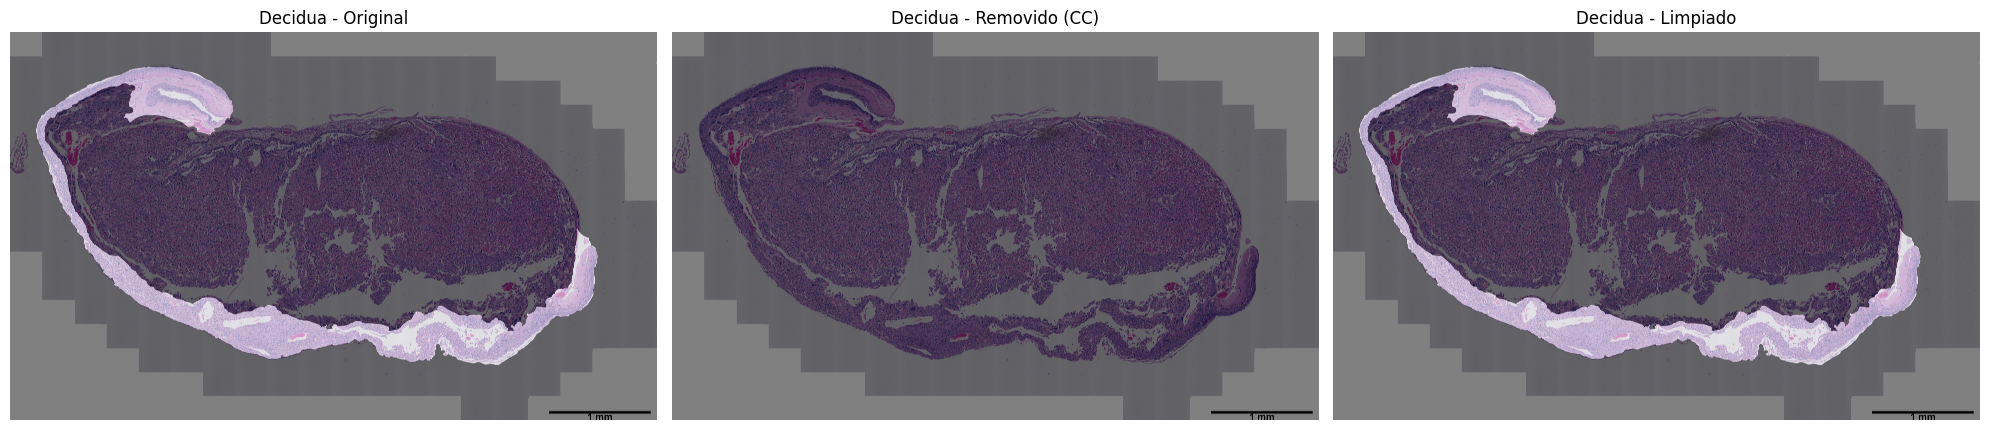

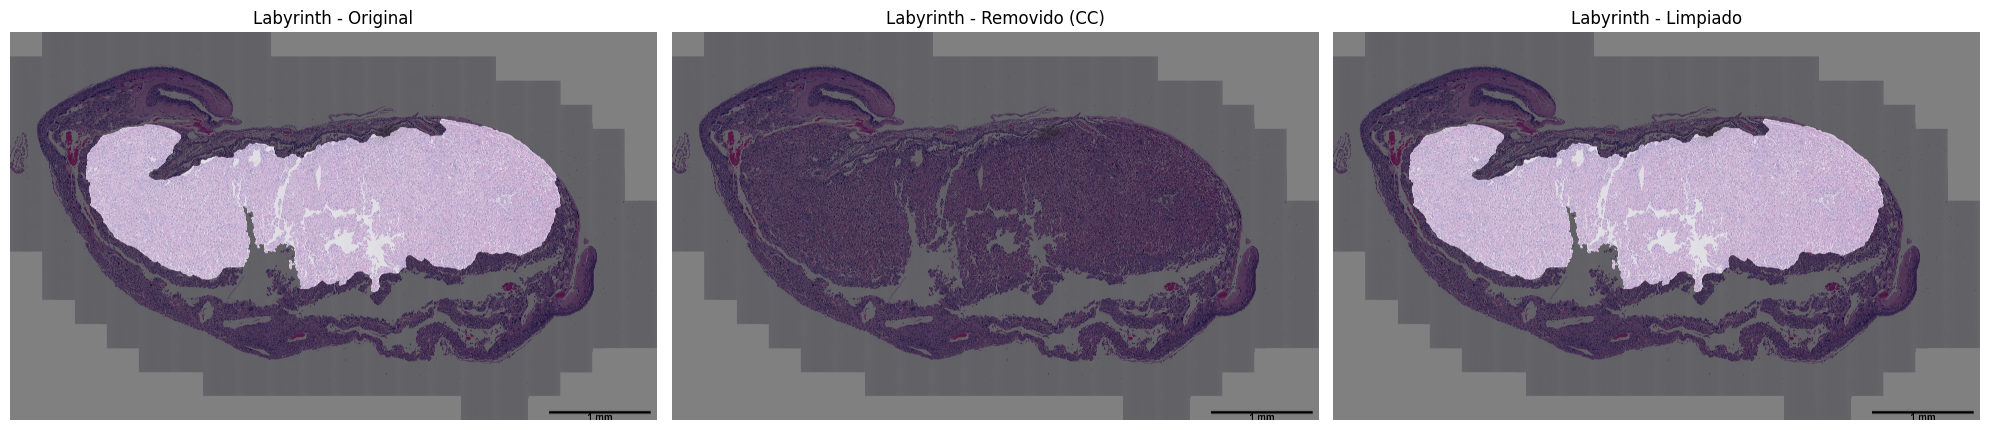

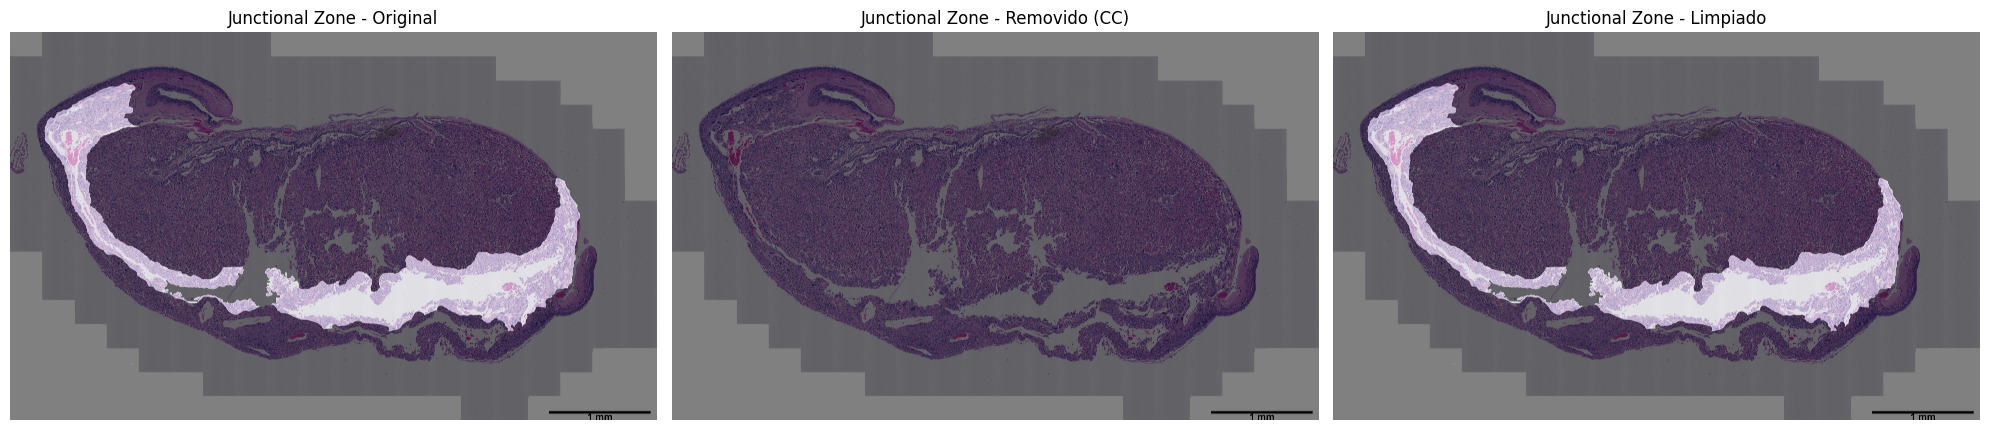

Resultado Connected Component: {'slide_id': 'slide_056', 'decidua_count': 2, 'labyrinth_count': 2, 'jz_count': 4, 'no_labeled_count': 0, 'total_features': 8}


In [34]:
# Parámetros para Connected Component
MIN_AREA = 100  # Área mínima para mantener un componente
USE_HSV_FILTER = False  # Combinar con filtrado HSV
SAT_THRESHOLD = 50
VALUE_THRESHOLD = 200

# Probar con un slide
slide_id = "slide_056"
result_cc = process_slide_cleaning_cc(
    slide_id,
    min_area=MIN_AREA,
    use_hsv_filter=USE_HSV_FILTER,
    sat_threshold=SAT_THRESHOLD,
    value_threshold=VALUE_THRESHOLD,
    visualize=True,
    save=False
)
print("Resultado Connected Component:", result_cc)

### Procesar todos los slides con Connected Component

In [ ]:
# Procesar todos los slides
annot_files = sorted(INPUT_ANNOT_DIR.glob("slide_*.geojson"))
slide_ids = [f.stem for f in annot_files]

print(f"Procesando {len(slide_ids)} slides con Connected Component...")

results_cc = []
for slide_id in tqdm(slide_ids[:10]):  # Pruebas con 10 slides
    try:
        result = process_slide_cleaning_cc(
            slide_id,
            min_area=MIN_AREA,
            use_hsv_filter=USE_HSV_FILTER,
            sat_threshold=SAT_THRESHOLD,
            value_threshold=VALUE_THRESHOLD,
            visualize=False,
            save=False
        )
        if result:
            results_cc.append(result)
    except Exception as e:
        print(f"Error {slide_id}: {e}")

print(f"\nProcesados: {len(results_cc)} slides")

In [ ]:
# Resumen de resultados
import pandas as pd

df_cc = pd.DataFrame(results_cc)
print("Resumen de features por slide (Connected Component):")
print(df_cc.describe())
print(f"\nTotal slides: {len(df_cc)}")
print(f"Total Decidua: {df_cc['decidua_count'].sum()}")
print(f"Total Labyrinth: {df_cc['labyrinth_count'].sum()}")
print(f"Total Junctional Zone: {df_cc['jz_count'].sum()}")
print(f"Total no_labeled: {df_cc['no_labeled_count'].sum()}")

### Comparar resultados HSV vs Connected Component

In [ ]:
# Comparar resultados de ambos métodos
print("Comparación de resultados:")
print("=" * 50)
print(f"Método HSV (original): {len(results)} slides procesados")
print(f"Método CC (nuevo):      {len(results_cc)} slides procesados")
print("=" * 50)

# Comparar slide por slide si hay datos
if len(results) > 0 and len(results_cc) > 0:
    # Crear DataFrames de ambos
    df_hsv = pd.DataFrame(results)
    
    # Unir por slide_id
    merged = df_hsv.merge(df_cc, on='slide_id', suffixes=('_hsv', '_cc'))
    
    print("\nDiferencias por slide:")
    print("-" * 50)
    
    for _, row in merged.iterrows():
        print(f"\nSlide: {row['slide_id']}")
        print(f"  Decidua: HSV={row['decidua_count_hsv']}, CC={row['decidua_count_cc']}, Diff={row['decidua_count_cc'] - row['decidua_count_hsv']}")
        print(f"  Labyrinth: HSV={row['labyrinth_count_hsv']}, CC={row['labyrinth_count_cc']}, Diff={row['labyrinth_count_cc'] - row['labyrinth_count_hsv']}")
        print(f"  JZ: HSV={row['jz_count_hsv']}, CC={row['jz_count_cc']}, Diff={row['jz_count_cc'] - row['jz_count_hsv']}")

## Guardar anotaciones procesadas con Connected Component

In [ ]:
# Guardar todas las anotaciones procesadas
OUTPUT_DIR_CC = DATA / "processed" / "clean_annotations_CC"
OUTPUT_DIR_CC.mkdir(exist_ok=True, parents=True)

print(f"Guardando anotaciones en: {OUTPUT_DIR_CC}")

for slide_id in tqdm(slide_ids):
    try:
        result = process_slide_cleaning_cc(
            slide_id,
            min_area=MIN_AREA,
            use_hsv_filter=USE_HSV_FILTER,
            sat_threshold=SAT_THRESHOLD,
            value_threshold=VALUE_THRESHOLD,
            visualize=False,
            save=True
        )
    except Exception as e:
        print(f"Error {slide_id}: {e}")

print(f"\nGuardadas todas las anotaciones en: {OUTPUT_DIR_CC}")